# Training the puck detector (E2a, re-scored on v4)

Team Challenge15 · Hockey Vision & Tactical Mapping

This notebook shows step by step how we trained and evaluated our puck detector, the model the app uses.
It is the same recipe as in the final report (§3 fine-tuning, §4 error analysis) and the experiment log
(`docs/experiments.md`, entries E2a and E3). The notebook calls the same code as our scripts:

| step | script |
|---|---|
| 1. Roboflow export → 640 px tiles, split by time | `scripts/make_puck_dataset.py` |
| 2. fine-tune YOLO26s on the tiles | `scripts/train_puck.py` |
| 3–4. training curves, validation of `best.pt` | Ultralytics output |
| 5. tiled inference on full frames, AP@50 | `scripts/eval_puck.py` |

**Running it.** Open the notebook with the project's `.venv` as kernel. Without retraining it runs in
about a minute (it reads the saved run and validates `best.pt`). Set `RUN_TRAINING = True` to train
again (about 25 min on an RTX 4060 Laptop). The dataset (`data/`) is not in the submission zip
because of its size, so the cells that read it only run on our own PCs; their output is saved in
the notebook.

In [1]:
import json, os, sys
from pathlib import Path

# work from the repository root, so all paths match the scripts and the log
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "scripts")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import ultralytics
from ultralytics import YOLO

from eval_puck import average_precision, load_gt, match, predict_tiled  # our own evaluation code
%matplotlib inline

DATA = Path("data/puck_tiles/fillempje_v4_tiles640")          # tiled dataset v4 (built in step 1)
RUN = Path("outputs/train/fillempje_v3_yolo26s_puck_640")      # the E2a run: weights used by the app
RUN_TRAINING = False                                            # True = train again (about 25 min on a GPU)

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

ultralytics 8.4.178 | torch 2.11.0+cu128 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. The dataset

**Labels.** 63 frames of the clip, labelled in Roboflow (version v4): 40 with a puck, 23 verified empty
(the puck was hidden; useful as negatives). Every label was reviewed by a person (report §2).

**Split by time, not randomly.** Neighbouring frames are near-duplicates, so a random split would put
the same puck in train and val. Frames ≥ 4200 (the last ~20% of the clip) are validation.

In [2]:
frames = pd.read_csv(DATA / "frames.csv")
summary = frames.groupby("split").agg(frames=("frame", "size"), with_puck=("n_pucks", lambda s: int((s > 0).sum())),
                                      pucks=("n_pucks", "sum"), first_frame=("frame", "min"), last_frame=("frame", "max"))
summary

,frames,with_puck,pucks,first_frame,last_frame
split,,,,,
train,39,31,31,60,4170
val,24,9,9,4200,5010


**Why tiles.** The puck is only 6–10 px in the 1920×1080 frame. Resizing the whole frame to 640 px
would shrink it to 2–3 px, smaller than one cell of YOLO's finest feature map (stride 8). So we cut
**640×640 tiles at native resolution**: the model sees the puck at its real size.

- Train: 8 random crops that contain the puck (at a random position) + 16 crops without a puck per
  labelled frame. There is only one puck and it is labelled, so the rest of the frame is a guaranteed
  negative (skates, stick tape, ads).
- Val: the full overlapping tile grid that inference uses (8 tiles per frame), so validation measures
  the real situation.

The dataset was built with:
```
python scripts/make_puck_dataset.py --export data/roboflow/pluhchallenge_v4 --val-from-frame 4200 --name fillempje_v4_tiles640
```

In [3]:
def count(split):
    labels = list((DATA / "labels" / split).glob("*.txt"))
    n_pos = sum(1 for p in labels if p.read_text().strip())
    return {"tiles": len(list((DATA / "images" / split).glob("*.jpg"))), "tiles with a puck": n_pos}

pd.DataFrame({s: count(s) for s in ("train", "val")})

,train,val
tiles,872,192
tiles with a puck,248,28


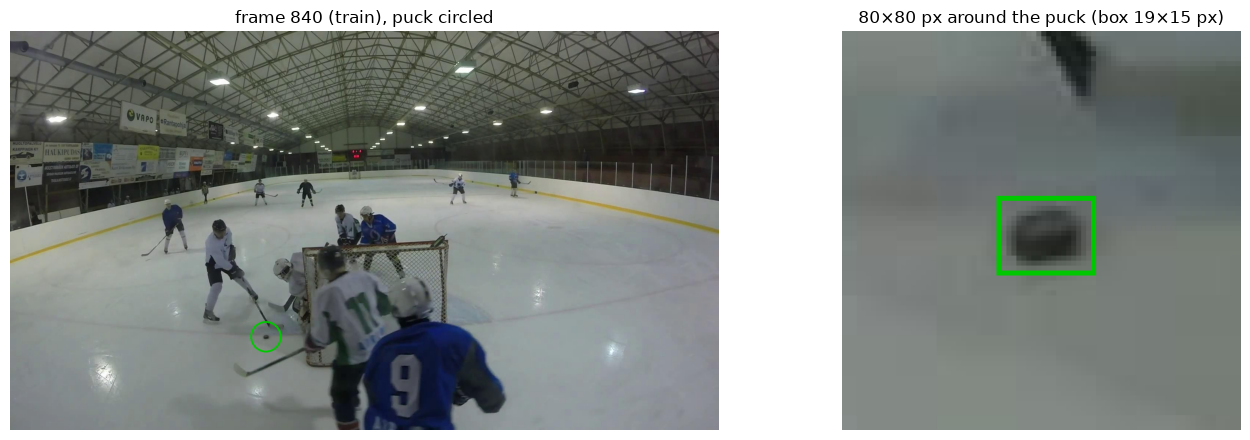

In [4]:
# one labelled frame and a few training tiles with their puck box
fr = frames[(frames.split == "train") & (frames.n_pucks > 0)].iloc[5]
img = cv2.imread(fr["image"])
gt = load_gt(fr["image"], img.shape[1], img.shape[0])[0].astype(int)
cx, cy = (gt[:2] + gt[2:]) // 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
full = img.copy()
cv2.circle(full, (int(cx), int(cy)), 40, (0, 200, 0), 4)
axes[0].imshow(cv2.cvtColor(full, cv2.COLOR_BGR2RGB)); axes[0].set_title(f"frame {fr['frame']} (train), puck circled")
crop = img[cy - 40:cy + 40, cx - 40:cx + 40].copy()
cv2.rectangle(crop, (gt[0] - cx + 40, gt[1] - cy + 40), (gt[2] - cx + 40, gt[3] - cy + 40), (0, 200, 0), 1)
axes[1].imshow(cv2.cvtColor(cv2.resize(crop, None, fx=4, fy=4, interpolation=cv2.INTER_NEAREST), cv2.COLOR_BGR2RGB))
axes[1].set_title(f"80×80 px around the puck (box {gt[2]-gt[0]}×{gt[3]-gt[1]} px)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 2. Training

We start from **COCO-pretrained YOLO26s** (transfer learning: the backbone already knows edges, blobs
and textures, so 31 training pucks are enough to learn one new class). All layers are trained.

| setting | value | why |
|---|---|---|
| imgsz | 640 | = tile size, so the puck keeps its native size |
| epochs / batch | 100 / 16 | `best.pt` = the epoch with the best val fitness |
| scale | 0.2 (default 0.5) | a stronger zoom-out would make a 6 px puck 3 px: invisible |
| fliplr / flipud | 0.5 / 0.0 | a mirrored rink is still a rink; upside-down ice never happens |
| degrees | 0 | the camera is upright; rotation would also bend the box |
| mosaic | 1.0 | 4 tiles in one image: more variety, more empty ice per batch |

The cell below is exactly the training call of `scripts/train_puck.py`. With `RUN_TRAINING = False` it
only shows the settings of the saved run.

In [5]:
if RUN_TRAINING:
    model = YOLO("yolo26s.pt")
    model.train(data=str(DATA / "data.yaml"), imgsz=640, epochs=100, batch=16, seed=0,
                project=str(Path("outputs/train").resolve()), name="notebook_E2a", exist_ok=True, workers=2,
                scale=0.2, fliplr=0.5, flipud=0.0, degrees=0.0, mosaic=1.0)
    RUN = Path("outputs/train/notebook_E2a")
else:
    import yaml
    args = yaml.safe_load((RUN / "args.yaml").read_text())
    print({k: args[k] for k in ["model", "imgsz", "epochs", "batch", "seed", "optimizer", "lr0",
                                "scale", "fliplr", "flipud", "degrees", "mosaic", "close_mosaic"]})

{'model': 'yolo26s.pt', 'imgsz': 640, 'epochs': 100, 'batch': 16, 'seed': 0, 'optimizer': 'auto', 'lr0': 0.01, 'scale': 0.2, 'fliplr': 0.5, 'flipud': 0.0, 'degrees': 0.0, 'mosaic': 1.0, 'close_mosaic': 10}


## 3. Training curves

YOLO26 has three losses: **box** (box position, IoU based), **cls** (puck or background) and **l1**
(box regression). The train losses keep falling, but the val losses and val mAP flatten after about
20–30 epochs: with 31 training pucks the model starts to memorise them (overfitting). That is why we
keep `best.pt` (the best val epoch) and not the last epoch.

The curves were logged during training, on the v3 val tiles (f5070 still in it). That is why their peak (0.63 at epoch 19) is a little lower than the v4 score in step 4.

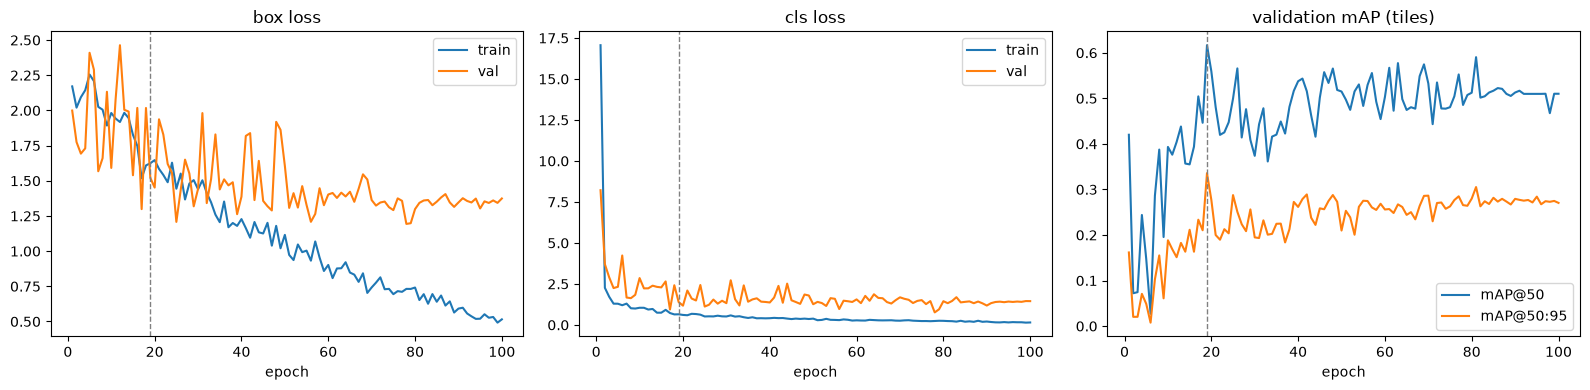

best epoch (best.pt): 19


In [6]:
res = pd.read_csv(RUN / "results.csv")
res.columns = res.columns.str.strip()
fitness = 0.1 * res["metrics/mAP50(B)"] + 0.9 * res["metrics/mAP50-95(B)"]   # how Ultralytics picks best.pt
best = int(res.loc[fitness.idxmax(), "epoch"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for loss in ("box", "cls"):
    axes[0 if loss == "box" else 1].plot(res["epoch"], res[f"train/{loss}_loss"], label="train")
    axes[0 if loss == "box" else 1].plot(res["epoch"], res[f"val/{loss}_loss"], label="val")
    axes[0 if loss == "box" else 1].set_title(f"{loss} loss")
axes[2].plot(res["epoch"], res["metrics/mAP50(B)"], label="mAP@50")
axes[2].plot(res["epoch"], res["metrics/mAP50-95(B)"], label="mAP@50:95")
axes[2].set_title("validation mAP (tiles)")
for a in axes:
    a.axvline(best, color="grey", ls="--", lw=1); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()
print("best epoch (best.pt):", best)

## 4. Validation of `best.pt` on the val tiles (v4)

The E2a model was trained on v3. After the error analysis we removed one wrong val label (f5070, a
stick blade) and generated v4, so here we score the same weights on the v4 val tiles (E3).

In [7]:
model = YOLO(RUN / "weights" / "best.pt")
m = model.val(data=str(DATA / "data.yaml"), imgsz=640, batch=16, plots=False, verbose=False,
              project="outputs/notebook", name="val", exist_ok=True)
print(f"tile mAP@50 = {m.box.map50:.3f}   tile mAP@50:95 = {m.box.map:.3f}   "
      f"precision = {m.box.mp:.3f}   recall = {m.box.mr:.3f}")

Ultralytics 8.4.178  Python-3.12.6 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs


                   all        192         28      0.872      0.571       0.68       0.41


Speed: 2.0ms preprocess, 12.4ms inference, 0.0ms loss, 0.3ms postprocess per image


tile mAP@50 = 0.680   tile mAP@50:95 = 0.410   precision = 0.872   recall = 0.571


## 5. Evaluation on full frames (how the app uses the model)

In the app a whole 1080p frame goes in. We cover it with 8 overlapping 640 px tiles (overlap 160 px,
larger than a puck), predict every tile, shift the boxes back to frame coordinates and merge them with
a second NMS step (the same puck can be found by two tiles). Then we match predictions to the labels
(IoU ≥ 0.5): AP@50 over all thresholds, and TP / FP / FN at our operating threshold conf 0.25.

In [8]:
val = frames[frames.split == "val"]
scores_all, tp_all, n_gt, TP, FP, FN = [], [], 0, 0, 0, 0
for _, fr in val.iterrows():
    img = cv2.imread(fr["image"])
    gts = load_gt(fr["image"], img.shape[1], img.shape[0])
    boxes, scores = predict_tiled(model, img, tile=640, overlap=160, conf=0.01)   # low conf: for the PR curve
    tp = match(boxes, scores, gts)
    scores_all += list(scores); tp_all += list(tp); n_gt += len(gts)
    keep = scores >= 0.25                                                       # operating point
    tp_c = match(boxes[keep], scores[keep], gts)
    TP += int(tp_c.sum()); FP += int((~tp_c).sum()); FN += len(gts) - int(tp_c.sum())

ap50 = average_precision(np.array(scores_all), np.array(tp_all, bool), n_gt)
print(f"{len(val)} val frames, {n_gt} pucks")
print(f"at conf 0.25: TP {TP} / FP {FP} / FN {FN}   ->   AP@50 (full frames) = {ap50:.2f}")
print("pretrained baseline (COCO 'sports ball', whole frame): TP 0 / FP 0 / FN 9, AP@50 0.02 (E3)")

24 val frames, 9 pucks
at conf 0.25: TP 6 / FP 1 / FN 3   ->   AP@50 (full frames) = 0.72
pretrained baseline (COCO 'sports ball', whole frame): TP 0 / FP 0 / FN 9, AP@50 0.02 (E3)


## 6. How stable is this? Three seeds

One run says little with 9 val pucks, so we retrained the same recipe on v4 with seeds 0, 1 and 2 (E3).
Seed 0 gave exactly the same model as E2a, so training is reproducible.

In [9]:
rows = []
for s in (0, 1, 2):
    p = Path(f"outputs/train/v4_E2a_s{s}/metrics.json")
    if p.exists():
        rows.append(json.loads(p.read_text()))
seeds = pd.DataFrame(rows).set_index("run")[["precision", "recall", "mAP50", "mAP50_95"]]
print(seeds.to_string())
print(f"\nmean ± std: mAP@50 {seeds.mAP50.mean():.3f} ± {seeds.mAP50.std():.3f}, "
      f"mAP@50:95 {seeds.mAP50_95.mean():.3f} ± {seeds.mAP50_95.std():.3f}")

           precision  recall  mAP50  mAP50_95
run                                          
v4_E2a_s0      0.872   0.571  0.680     0.410
v4_E2a_s1      0.788   0.666  0.604     0.377
v4_E2a_s2      0.755   0.571  0.475     0.299

mean ± std: mAP@50 0.586 ± 0.104, mAP@50:95 0.362 ± 0.057


## Conclusion

- Fine-tuning on native-resolution tiles turned the puck from almost never found (0/9 val pucks) into
  found in 6/9, with AP@50 0.72 on full frames and tile mAP@50 0.68 / mAP@50:95 0.41.
- The seed alone moves tile mAP@50 by about ±0.10: our model is the best of three seeds; the typical
  value is 0.59 ± 0.10.
- The remaining errors come from the data (the stick-blade question, few blurred pucks), not from the
  threshold: see the error analysis in the report (§4) and `docs/error_analysis.md`.